# Day 12 - Model Evaluation in Machine Learning

**Internship Domain:** Artificial Intelligence and Machine Learning  
**Topic:** Accuracy, Precision, Recall, F1 Score, and Confusion Matrix

## Objective
Evaluate the Logistic Regression and Decision Tree models from Day 11. The Breast Cancer Wisconsin dataset is for educational practice only and is not a medical diagnostic tool.

## 1. Load and prepare data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

df = pd.read_csv('../data/breast_cancer_wisconsin.csv')
X, y = df.drop(columns='target'), df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Dataset shape:', df.shape)
print('Training:', X_train.shape, 'Testing:', X_test.shape)

Dataset shape: (569, 31)
Training: (455, 30) Testing: (114, 30)


## 2. Train the Day 11 models

In [5]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=42)),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}
for model in models.values():
    model.fit(X_train, y_train)
predictions = {name: model.predict(X_test) for name, model in models.items()}

## 3. Calculate metrics
Macro averages give both classes equal weight.

In [3]:
results = []
for name, pred in predictions.items():
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0), 'Recall (macro)': recall_score(y_test, pred, average='macro', zero_division=0), 'F1 Score (macro)': f1_score(y_test, pred, average='macro', zero_division=0)})
metrics_df = pd.DataFrame(results)
print(metrics_df.round(4).to_string(index=False))
metrics_df.to_csv('../outputs/model_evaluation_metrics.csv', index=False)

              Model  Accuracy  Precision (macro)  Recall (macro)  F1 Score (macro)
Logistic Regression    0.9825             0.9812          0.9812            0.9812
      Decision Tree    0.9123             0.9019          0.9157            0.9075


## 4. Confusion matrices and classification reports
Rows are actual classes and columns are predicted classes. Off-diagonal cells are errors.

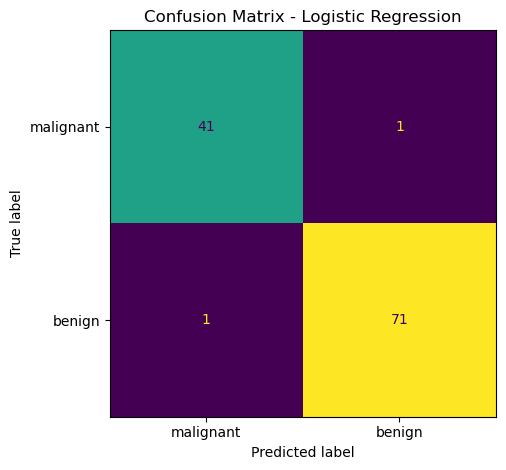

Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



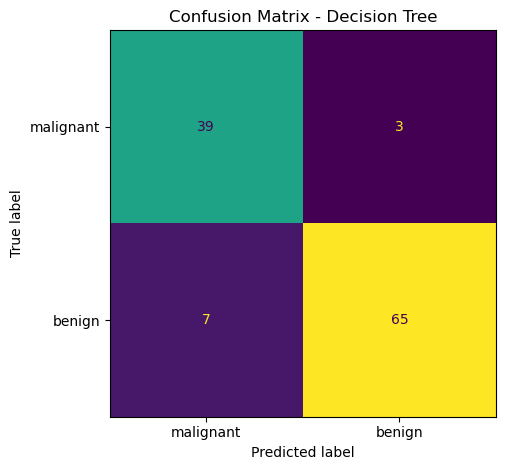

Decision Tree
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [4]:
class_names = ['malignant', 'benign']
for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(values_format='d', colorbar=False)
    plt.title(f'Confusion Matrix - {name}')
    plt.tight_layout()
    plt.show()
    print(name)
    print(classification_report(y_test, pred, labels=[0, 1], target_names=class_names, zero_division=0))

## 5. Which metric is most useful?
- **Accuracy:** overall proportion of correct predictions.
- **Precision:** how reliable predictions for a class are.
- **Recall:** proportion of actual class cases identified.
- **F1 score:** balances precision and recall.

For this medical-related educational dataset, recall for the malignant class deserves special attention because a false negative could be serious. Inspect class-wise metrics and the confusion matrix alongside accuracy. This is not a diagnostic tool.

## 6. Conclusion
This task evaluates the Day 11 models using multiple metrics and confusion matrices. Results depend on the data split and model settings; real-world medical use would require independent validation and expert review.